# 01 · Análisis exploratorio: ¿quién abandona el banco y por qué?

**Problema de negocio.** Un banco pierde aproximadamente 1 de cada 6 clientes de tarjeta de crédito. Captar un cliente nuevo cuesta varias veces más que retener uno existente, así que el banco quiere **identificar con anticipación** a los clientes con alta probabilidad de irse para actuar antes (llamada, oferta, mejora de producto).

**Dataset.** `BankChurners.csv` (Kaggle, *Credit Card Customers*): 10,127 clientes, 23 columnas. Cada fila es un cliente con datos demográficos, su relación con el banco y su comportamiento transaccional de los últimos 12 meses. La etiqueta `Attrition_Flag` indica si el cliente cerró su cuenta.

**Objetivo de este notebook.** Entender los datos y extraer conclusiones de negocio **antes** de modelar: qué variables separan a los que se van de los que se quedan, y qué implicaciones tiene eso para el modelo y para la gerencia.

> Nota metodológica: el EDA es descriptivo y se hace sobre el dataset completo. Las decisiones de modelado (hiperparámetros, umbral) se toman en el notebook 02 solo con validación cruzada sobre el conjunto de entrenamiento, nunca con el de test.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Permite importar los módulos de src/ desde la carpeta notebooks/
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src.datos import (COLUMNAS_LEAKAGE, COLUMNAS_REDUNDANTES, COLUMNA_OBJETIVO,
                       cargar_datos, limpiar_datos)
from src.interpretacion import DICCIONARIO_VARIABLES, traducir
from src.preprocesamiento import COLUMNAS_CATEGORICAS, COLUMNAS_NUMERICAS, resumen_columnas

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

FIGURAS = RAIZ / "outputs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Carga y primera inspección

In [2]:
df_raw = cargar_datos()
print(f"Filas: {df_raw.shape[0]:,}  |  Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 10,127  |  Columnas: 23


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [3]:
resumen_columnas(df_raw)

,tipo,n_unicos,ejemplo
CLIENTNUM,int64,10127,768805383
Attrition_Flag,str,2,Existing Customer
Customer_Age,int64,45,45
Gender,str,2,M
Dependent_count,int64,6,3
Education_Level,str,7,High School
Marital_Status,str,4,Married
Income_Category,str,6,$60K - $80K
Card_Category,str,4,Blue
Months_on_book,int64,44,39


In [4]:
print("Valores nulos por columna (total):", int(df_raw.isna().sum().sum()))
print("Clientes duplicados por CLIENTNUM:", int(df_raw["CLIENTNUM"].duplicated().sum()))

Valores nulos por columna (total): 0
Clientes duplicados por CLIENTNUM: 0


### 1.1 Fuga de información (leakage): dos columnas que hay que eliminar

Las dos últimas columnas se llaman `Naive_Bayes_Classifier_Attrition_Flag_..._1` y `..._2`. Son las **probabilidades de otro modelo** que alguien entrenó usando la propia etiqueta de abandono y las dejó en el CSV. Si las usamos como predictoras, nuestro modelo "copiaría" la respuesta y obtendría métricas irreales que jamás se repetirían con clientes nuevos.

Comprobación: su correlación con la etiqueta es casi perfecta.

In [5]:
objetivo_tmp = (df_raw["Attrition_Flag"] == "Attrited Customer").astype(int)
for col in COLUMNAS_LEAKAGE:
    print(f"corr(objetivo, {col[:45]}...) = {objetivo_tmp.corr(df_raw[col]):.3f}")

corr(objetivo, Naive_Bayes_Classifier_Attrition_Flag_Card_Ca...) = 1.000
corr(objetivo, Naive_Bayes_Classifier_Attrition_Flag_Card_Ca...) = -1.000


También se elimina `Avg_Open_To_Buy`, porque es exactamente `Credit_Limit - Total_Revolving_Bal`: no aporta información y genera colinealidad perfecta en la regresión logística.

In [6]:
print("Avg_Open_To_Buy == Credit_Limit - Total_Revolving_Bal en todas las filas:",
      bool(np.allclose(df_raw["Avg_Open_To_Buy"], df_raw["Credit_Limit"] - df_raw["Total_Revolving_Bal"])))

df = limpiar_datos(df_raw)
print("Columnas tras limpieza:", df.shape[1])
df.head(3)

Avg_Open_To_Buy == Credit_Limit - Total_Revolving_Bal en todas las filas: True
Columnas tras limpieza: 21


,CLIENTNUM,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,abandono,Ticket_Promedio
0,768805383,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,1.335,1144,42,1.625,0.061,0,27.24
1,818770008,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,1.541,1291,33,3.714,0.105,0,39.12
2,713982108,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,2.594,1887,20,2.333,0.000,0,94.35


## 2. La variable objetivo: un problema desbalanceado

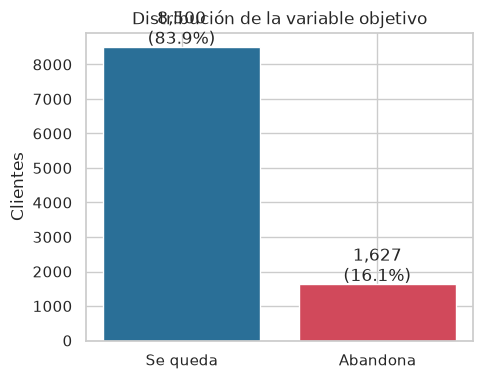

Tasa de abandono: 16.07%


In [7]:
conteo = df[COLUMNA_OBJETIVO].value_counts().rename({0: "Se queda", 1: "Abandona"})
tasa = df[COLUMNA_OBJETIVO].mean()

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(conteo.index, conteo.values, color=["#2a6f97", "#d1495b"])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 100, f"{v:,}\n({v / len(df):.1%})", ha="center")
ax.set(title="Distribución de la variable objetivo", ylabel="Clientes")
fig.savefig(FIGURAS / "01_distribucion_objetivo.png", bbox_inches="tight")
plt.show()
print(f"Tasa de abandono: {tasa:.2%}")

**Conclusión.** Solo el **16.1%** de los clientes abandona. Esto tiene dos consecuencias:

1. **La exactitud (accuracy) engaña.** Un modelo que diga "nadie abandona" acierta el 83.9% de las veces y no sirve para nada. Necesitamos métricas que miren a la clase minoritaria: recall, precisión, PR-AUC.
2. **Los modelos tienden a ignorar la clase pequeña.** Habrá que ponderar más los errores sobre los clientes que abandonan (se hace en el notebook 02 con `class_weight`).

## 3. Variables demográficas: ¿importa quién es el cliente?

Para cada variable categórica, calculamos la tasa de abandono por grupo. Si la variable discrimina, veremos grupos muy por encima o muy por debajo del 16% global.

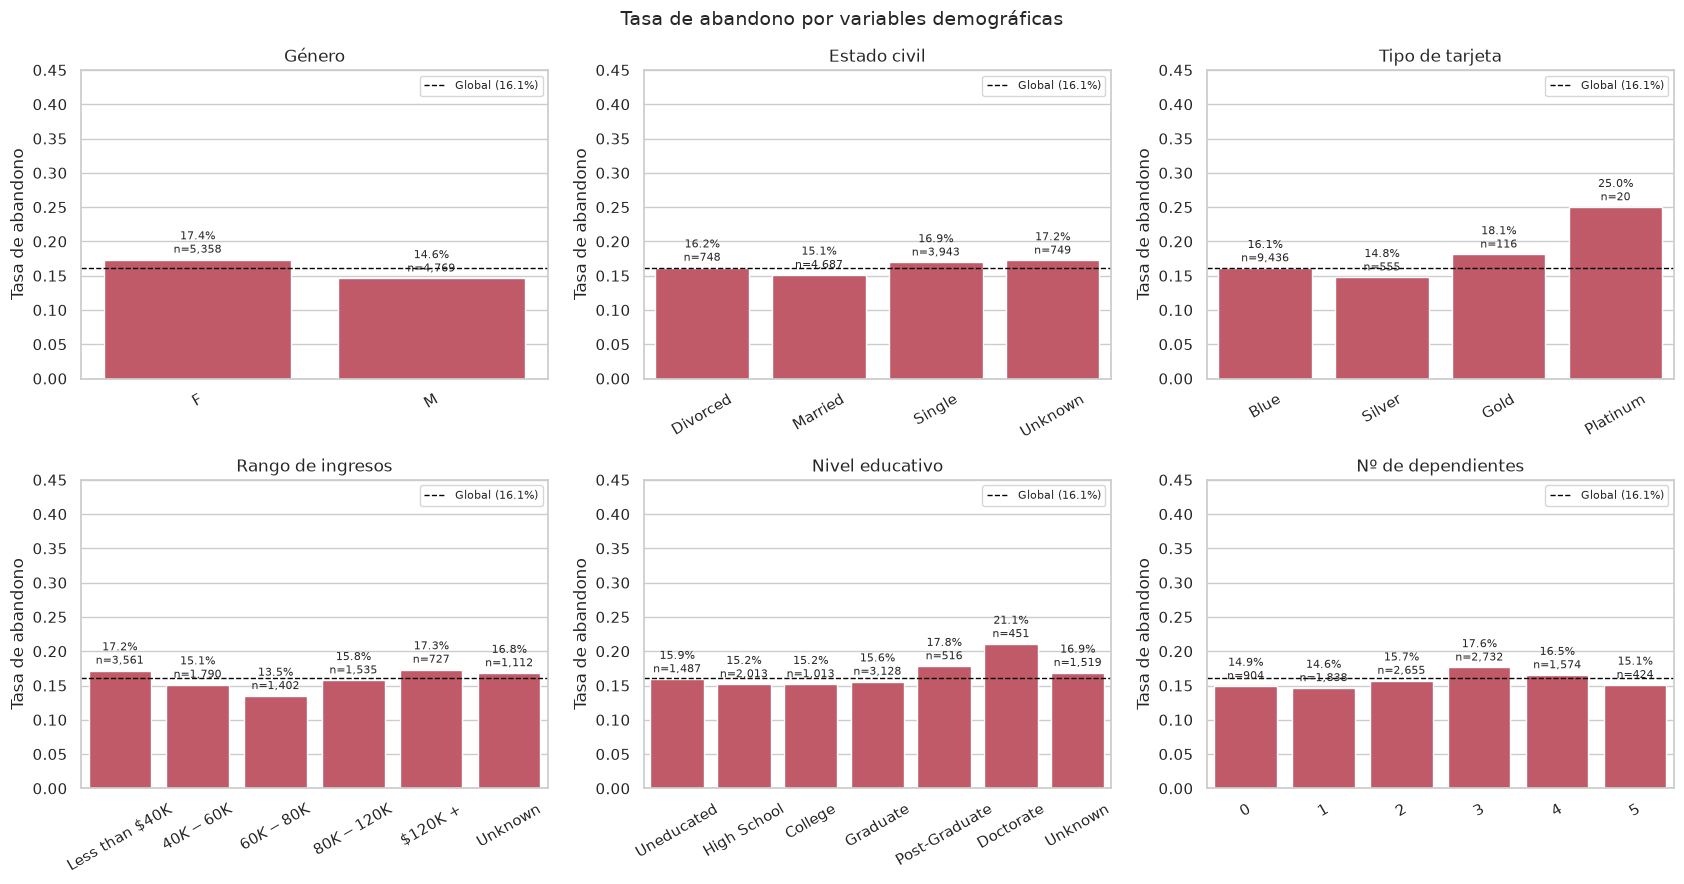

In [8]:
def tasa_abandono_por(df, columna, ax, orden=None):
    tabla = df.groupby(columna, observed=True)[COLUMNA_OBJETIVO].agg(["mean", "count"])
    if orden is not None:
        tabla = tabla.reindex(orden)
    tabla = tabla.reset_index()
    sns.barplot(data=tabla, x=columna, y="mean", ax=ax, color="#d1495b")
    ax.axhline(tasa, color="black", ls="--", lw=1, label=f"Global ({tasa:.1%})")
    ax.set(title=traducir(columna), xlabel="", ylabel="Tasa de abandono", ylim=(0, 0.45))
    ax.tick_params(axis="x", rotation=30)
    for i, fila in tabla.iterrows():
        ax.text(i, fila["mean"] + 0.01, f"{fila['mean']:.1%}\nn={int(fila['count']):,}", ha="center", fontsize=8)
    ax.legend(loc="upper right", fontsize=8)
    return tabla

orden_ingresos = ["Less than $40K", "$40K - $60K", "$60K - $80K", "$80K - $120K", "$120K +", "Unknown"]
orden_educacion = ["Uneducated", "High School", "College", "Graduate", "Post-Graduate", "Doctorate", "Unknown"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
tasa_abandono_por(df, "Gender", axes[0, 0])
tasa_abandono_por(df, "Marital_Status", axes[0, 1])
tasa_abandono_por(df, "Card_Category", axes[0, 2], orden=["Blue", "Silver", "Gold", "Platinum"])
tasa_abandono_por(df, "Income_Category", axes[1, 0], orden=orden_ingresos)
tasa_abandono_por(df, "Education_Level", axes[1, 1], orden=orden_educacion)
tasa_abandono_por(df, "Dependent_count", axes[1, 2])
fig.suptitle("Tasa de abandono por variables demográficas", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "01_demograficas.png", bbox_inches="tight")
plt.show()

**Conclusión de negocio.** La demografía **casi no explica el abandono**. Todas las categorías se mueven entre el 13% y el 21%, muy cerca del 16% global:

- Las mujeres abandonan un poco más que los hombres (17.4% vs 14.6%).
- Doctorado (21%) y Platinum (25%) destacan, pero Platinum son solo 20 clientes: no es una base para decidir nada.
- El ingreso no muestra tendencia: tanto los de menos de $40K como los de más de $120K rondan el 17%.

Implicación: una campaña de retención dirigida por "perfil sociodemográfico" sería tirar dinero. Hay que mirar **lo que el cliente hace**, no quién es.

## 4. Relación con el banco: productos, inactividad y contactos

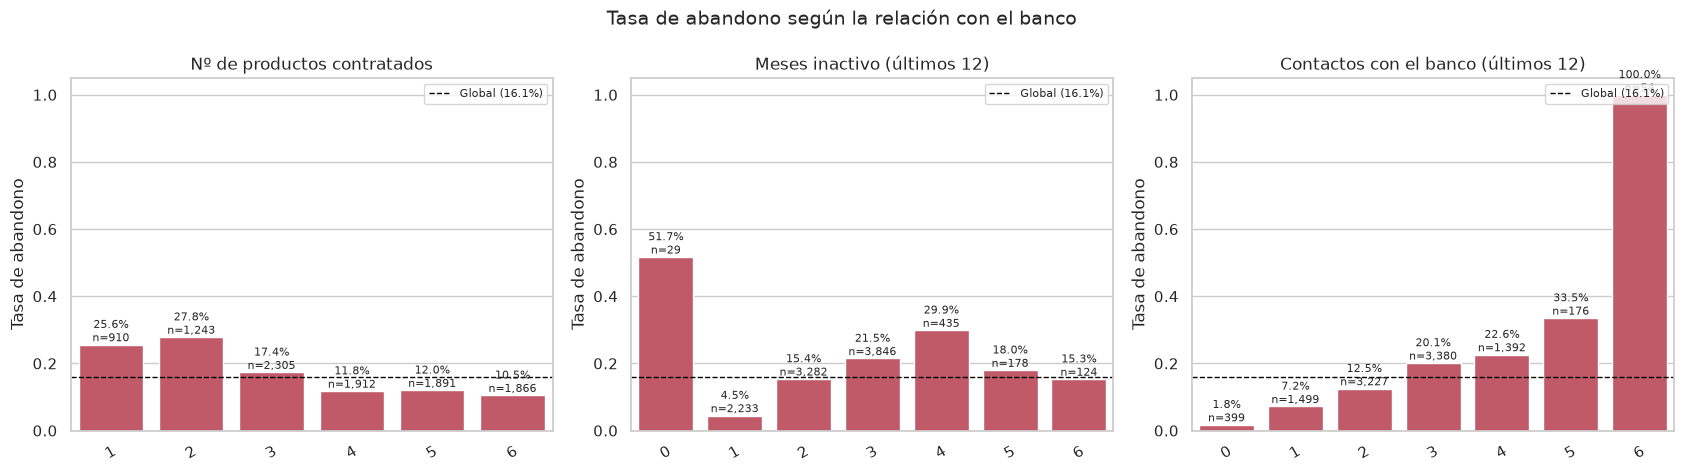

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
t_prod = tasa_abandono_por(df, "Total_Relationship_Count", axes[0])
t_inac = tasa_abandono_por(df, "Months_Inactive_12_mon", axes[1])
t_cont = tasa_abandono_por(df, "Contacts_Count_12_mon", axes[2])
for ax in axes:
    ax.set_ylim(0, 1.05)
fig.suptitle("Tasa de abandono según la relación con el banco", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "01_relacion_banco.png", bbox_inches="tight")
plt.show()

**Conclusiones de negocio.** Aquí sí aparecen señales fuertes:

1. **Pocos productos = alto riesgo.** Clientes con 1 o 2 productos abandonan al 26-28%; con 4 o más, al 10-12%. Un cliente "atado" a varios productos (cuenta, préstamo, seguro) tiene más fricción para irse. *Acción:* la venta cruzada no es solo ingreso adicional, es retención.
2. **Inactividad prolongada.** Con 1 mes inactivo el abandono es 4.5%; con 3 meses, 21.5%; con 4 meses, 30%. *Acción:* un cliente que lleva 3 meses sin usar la tarjeta ya está en zona de alerta. (El grupo con 0 meses inactivos tiene 52% pero son solo 29 clientes, probablemente cuentas muy nuevas.)
3. **Muchos contactos con el banco = cliente insatisfecho.** Con 0-1 contactos abandona el 2-7%; con 4, el 23%; con 5, el 34%; con 6, el **100%** (54 de 54). Un cliente que llama muchas veces no está contento. *Acción:* a partir del tercer contacto en un año, el caso debería escalar a retención.

## 5. Comportamiento transaccional: la señal más fuerte

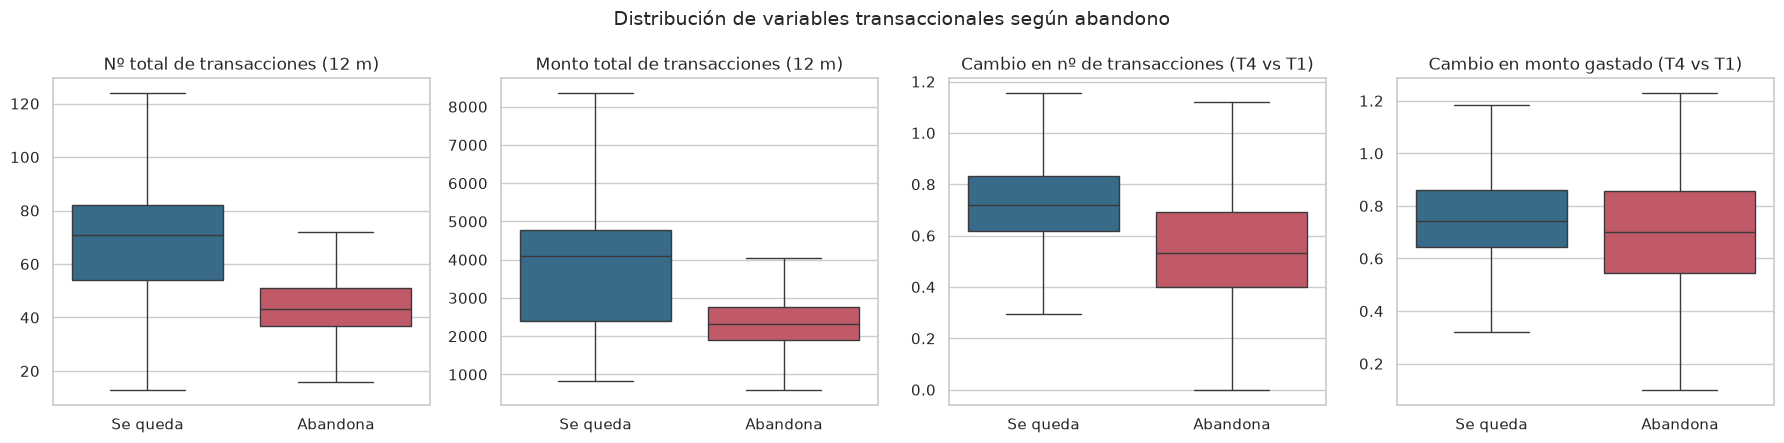

Mediana por grupo:


,Total_Trans_Ct,Total_Trans_Amt,Total_Ct_Chng_Q4_Q1,Total_Amt_Chng_Q4_Q1
abandono,,,,
Se queda,71.0,4100.0,0.72,0.74
Abandona,43.0,2329.0,0.53,0.70


In [10]:
variables_transaccion = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, variables_transaccion):
    sns.boxplot(data=df, x=COLUMNA_OBJETIVO, y=col, ax=ax, hue=COLUMNA_OBJETIVO,
                palette={0: "#2a6f97", 1: "#d1495b"}, legend=False, showfliers=False)
    ax.set(title=traducir(col), xlabel="", ylabel="")
    ax.set_xticks([0, 1], labels=["Se queda", "Abandona"])
fig.suptitle("Distribución de variables transaccionales según abandono", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "01_transaccional_boxplots.png", bbox_inches="tight")
plt.show()

print("Mediana por grupo:")
df.groupby(COLUMNA_OBJETIVO)[variables_transaccion].median().rename(index={0: "Se queda", 1: "Abandona"}).round(2)

In [11]:
# Tasa de abandono por quintil: divide a los clientes en 5 grupos del mismo tamaño
# según la variable y mide cuánto abandona cada grupo.
def tasa_por_quintil(df, col):
    grupos = pd.qcut(df[col], 5, duplicates="drop")
    return df.groupby(grupos, observed=True)[COLUMNA_OBJETIVO].agg(tasa="mean", clientes="count")

for col in ["Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1"]:
    print(f"\n{traducir(col)}")
    print(tasa_por_quintil(df, col).round(3).to_string())


Nº total de transacciones (12 m)
                 tasa  clientes
Total_Trans_Ct                 
(9.999, 41.0]   0.327      2076
(41.0, 61.0]    0.348      2089
(61.0, 73.0]    0.066      2077
(73.0, 83.0]    0.033      1914
(83.0, 139.0]   0.011      1971

Cambio en nº de transacciones (T4 vs T1)
                      tasa  clientes
Total_Ct_Chng_Q4_Q1                 
(-0.001, 0.545]      0.421      2032
(0.545, 0.657]       0.153      2028
(0.657, 0.745]       0.077      2031
(0.745, 0.853]       0.080      2017
(0.853, 3.714]       0.071      2019


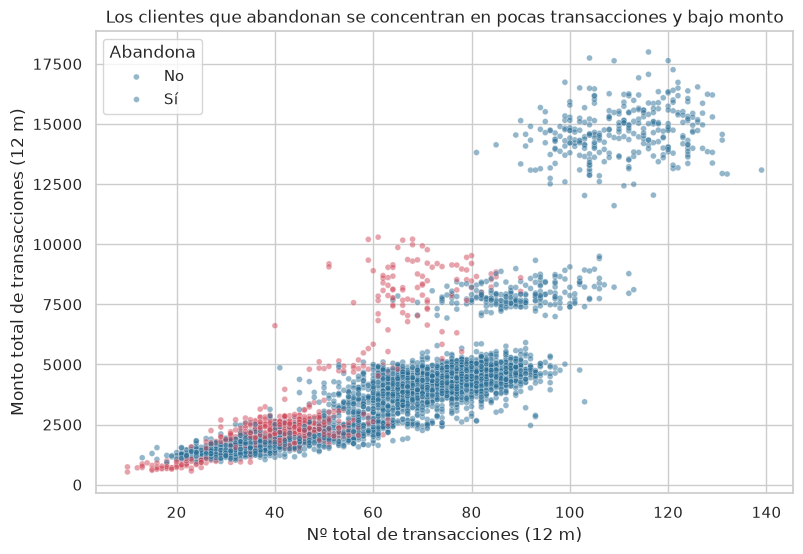

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))
muestra = df.sample(4000, random_state=0)
sns.scatterplot(data=muestra, x="Total_Trans_Ct", y="Total_Trans_Amt", hue=COLUMNA_OBJETIVO,
                palette={0: "#2a6f97", 1: "#d1495b"}, alpha=0.5, s=18, ax=ax)
ax.set(xlabel=traducir("Total_Trans_Ct"), ylabel=traducir("Total_Trans_Amt"),
       title="Los clientes que abandonan se concentran en pocas transacciones y bajo monto")
ax.legend(title="Abandona", labels=["No", "Sí"])
fig.savefig(FIGURAS / "01_scatter_transacciones.png", bbox_inches="tight")
plt.show()

**Conclusiones de negocio.**

1. **El uso de la tarjeta es el mejor termómetro.** El cliente típico que abandona hizo **43 transacciones** al año; el que se queda, **71**. En monto: $2,329 frente a $4,100. El 40% de clientes con menos transacciones concentra tasas de abandono del 33-35%; el 20% más activo, solo 1.1%.
2. **La caída de actividad es la alerta temprana.** `Total_Ct_Chng_Q4_Q1` compara las transacciones del último trimestre con el primero. En el quintil con mayor caída (ratio < 0.55) abandona el **42%**; en el resto, entre 7% y 15%. El cliente no se va de golpe: **primero reduce su uso, después cierra**. Esto es lo que permite actuar a tiempo.
3. El gráfico de dispersión muestra que los que abandonan forman una nube clara en la esquina inferior izquierda (pocas transacciones, bajo monto). Un modelo de árboles puede aprender esa frontera fácilmente.

### 5.1 Ticket promedio: ¿importa el tamaño de cada compra?

`Ticket_Promedio` es una variable derivada creada en `src/datos.py`: monto total / nº de transacciones, es decir, cuánto gasta el cliente en cada compra. Primero la miramos sola y después condicionada al nº de transacciones.

Tasa de abandono por cuartil de ticket promedio (sin condicionar):
                 tasa  clientes
cuartil_ticket                 
Q1 (bajo)       0.186      2532
Q2              0.150      2532
Q3              0.127      2531
Q4 (alto)       0.180      2532


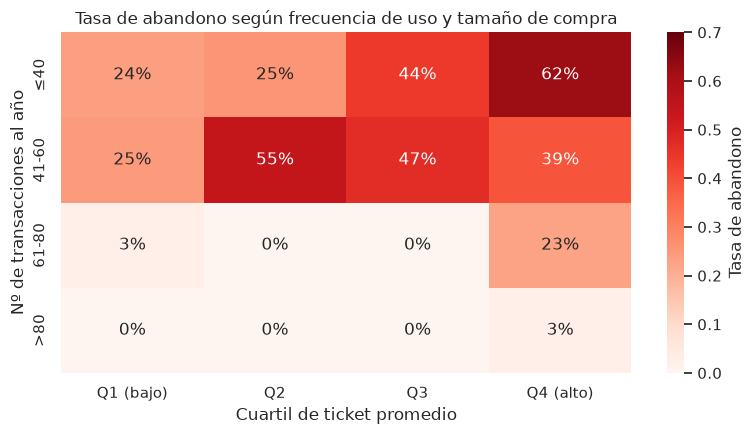

Clientes por celda:
cuartil_ticket       Q1 (bajo)   Q2    Q3  Q4 (alto)
rango_transacciones                                 
≤40                        902  506   340        190
41-60                      998  459   360        292
61-80                      460  839  1390        841
>80                        172  728   441       1209


In [13]:
df_tmp = df.copy()
df_tmp["cuartil_ticket"] = pd.qcut(df_tmp["Ticket_Promedio"], 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
df_tmp["rango_transacciones"] = pd.cut(df_tmp["Total_Trans_Ct"], [0, 40, 60, 80, 200], labels=["≤40", "41-60", "61-80", ">80"])

print("Tasa de abandono por cuartil de ticket promedio (sin condicionar):")
print(df_tmp.groupby("cuartil_ticket", observed=True)[COLUMNA_OBJETIVO].agg(tasa="mean", clientes="count").round(3).to_string())

tabla = df_tmp.pivot_table(index="rango_transacciones", columns="cuartil_ticket", values=COLUMNA_OBJETIVO, aggfunc="mean", observed=True)
conteo = df_tmp.pivot_table(index="rango_transacciones", columns="cuartil_ticket", values=COLUMNA_OBJETIVO, aggfunc="count", observed=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(tabla, annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=0.7, ax=ax, cbar_kws={"label": "Tasa de abandono"})
ax.set(xlabel="Cuartil de ticket promedio", ylabel="Nº de transacciones al año",
       title="Tasa de abandono según frecuencia de uso y tamaño de compra")
fig.tight_layout()
fig.savefig(FIGURAS / "01_ticket_promedio.png", bbox_inches="tight")
plt.show()
print("Clientes por celda:")
print(conteo.to_string())

**Conclusión de negocio.** Sola, la variable parece casi irrelevante: todos los cuartiles están entre 12% y 20%. Pero **condicionada a la frecuencia de uso cambia por completo**:

- Entre clientes con ≤40 transacciones al año, los de ticket bajo abandonan al 24% y los de ticket alto al **62%**.
- Entre clientes con 61-80 transacciones, los tres primeros cuartiles abandonan casi al 0%, pero el de ticket alto al **23%**.

Lectura: a igual número de transacciones, **el cliente que concentra su gasto en pocas compras grandes es el que se va**; el que usa la tarjeta para muchas compras pequeñas del día a día se queda. El hábito retiene; la compra grande puntual, no. Esta es la razón de crear la variable: los modelos de árboles podrían aprender la interacción solos, pero la regresión logística no, y para negocio es mucho más fácil hablar de "ticket promedio" que de "interacción entre monto y número".

## 6. Saldo y utilización del crédito

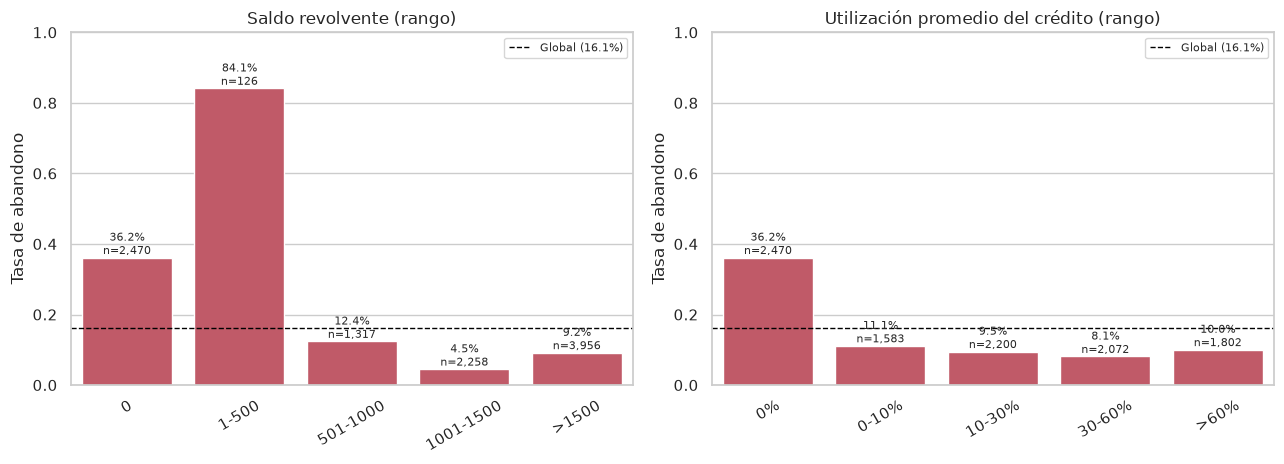

In [14]:
df_tmp = df.copy()
df_tmp["rango_saldo_revolvente"] = pd.cut(df_tmp["Total_Revolving_Bal"], [-1, 0, 500, 1000, 1500, 3000],
                                          labels=["0", "1-500", "501-1000", "1001-1500", ">1500"])
df_tmp["rango_utilizacion"] = pd.cut(df_tmp["Avg_Utilization_Ratio"], [-0.01, 0, 0.1, 0.3, 0.6, 1.0],
                                     labels=["0%", "0-10%", "10-30%", "30-60%", ">60%"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
tasa_abandono_por(df_tmp, "rango_saldo_revolvente", axes[0])
tasa_abandono_por(df_tmp, "rango_utilizacion", axes[1])
axes[0].set(title="Saldo revolvente (rango)", ylim=(0, 1.0))
axes[1].set(title="Utilización promedio del crédito (rango)", ylim=(0, 1.0))
fig.tight_layout()
fig.savefig(FIGURAS / "01_saldo_utilizacion.png", bbox_inches="tight")
plt.show()

**Conclusión de negocio.** El **24% de los clientes tiene saldo revolvente cero** (no deben nada en la tarjeta) y ese grupo abandona al **36%**, más del doble que el promedio. Un cliente sin saldo no tiene ningún "ancla" financiera con el banco: cerrar la tarjeta no le cuesta nada. El rango 1-500 tiene una tasa altísima (84%) pero son 126 clientes, probablemente saldos residuales de cuentas que ya se estaban cerrando.

*Acción:* clientes con utilización 0% durante varios meses deberían recibir incentivos de uso (cashback, cuotas sin interés) antes de que se desvinculen del todo.

## 7. Correlaciones entre variables numéricas

Sirve para dos cosas: detectar redundancias que confundan a la regresión logística, y confirmar qué variables se relacionan con el abandono.

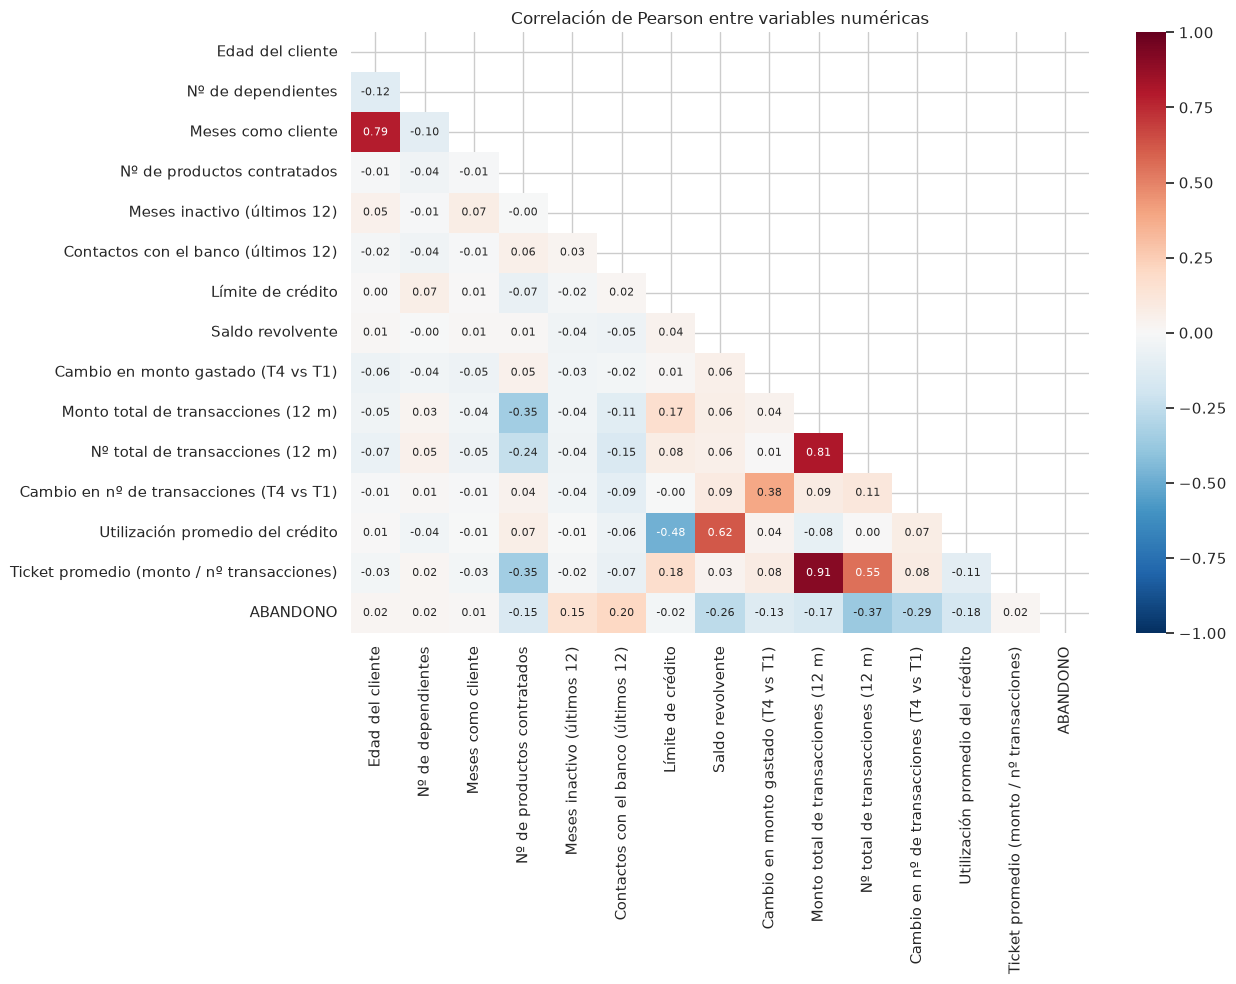

Correlación con el abandono (ordenada):
Total_Trans_Ct             -0.371
Total_Ct_Chng_Q4_Q1        -0.290
Total_Revolving_Bal        -0.263
Avg_Utilization_Ratio      -0.178
Total_Trans_Amt            -0.169
Total_Relationship_Count   -0.150
Total_Amt_Chng_Q4_Q1       -0.131
Credit_Limit               -0.024
Months_on_book              0.014
Ticket_Promedio             0.016
Customer_Age                0.018
Dependent_count             0.019
Months_Inactive_12_mon      0.152
Contacts_Count_12_mon       0.204


In [15]:
numericas = COLUMNAS_NUMERICAS + [COLUMNA_OBJETIVO]
corr = df[numericas].corr()
etiquetas = [traducir(c) if c != COLUMNA_OBJETIVO else "ABANDONO" for c in numericas]

fig, ax = plt.subplots(figsize=(13, 10))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación de Pearson entre variables numéricas")
fig.tight_layout()
fig.savefig(FIGURAS / "01_correlaciones.png", bbox_inches="tight")
plt.show()

print("Correlación con el abandono (ordenada):")
print(corr[COLUMNA_OBJETIVO].drop(COLUMNA_OBJETIVO).sort_values().round(3).to_string())

**Lectura.**

- Las correlaciones más fuertes con el abandono son negativas: nº de transacciones (-0.37), cambio en nº de transacciones (-0.29), saldo revolvente (-0.26), utilización (-0.18) y nº de productos (-0.15). Positivas: contactos con el banco (+0.20) e inactividad (+0.15). Coincide con todo lo visto.
- Hay pares muy correlacionados entre sí: monto y número de transacciones (0.81), límite de crédito y utilización, edad y meses como cliente (0.79). Esto no es un problema para los árboles, pero en la regresión logística hará que los coeficientes de esas variables se "repartan" el efecto y deban leerse con cuidado.

## 8. Resumen de conclusiones de negocio

| Hallazgo | Dato | Qué puede hacer el banco |
|---|---|---|
| La demografía no predice el abandono | Todas las categorías entre 13% y 21% | No segmentar campañas por edad, género o ingreso |
| Caída de actividad trimestral es la alerta temprana | Quintil con mayor caída: 42% abandono | Monitorear mensualmente el ratio T4/T1 y disparar alertas |
| Bajo uso de la tarjeta | Mediana 43 vs 71 transacciones/año | Incentivos de uso (cashback, promociones) para clientes de bajo volumen |
| Ticket alto con pocas transacciones | ≤40 transacciones: ticket bajo 24%, ticket alto 62% | Incentivar el uso cotidiano (compras pequeñas frecuentes), no solo compras grandes |
| Pocos productos contratados | 1-2 productos: 27%; 4+: 11% | Venta cruzada como herramienta de retención |
| Muchos contactos con el banco | 4+ contactos: 23-100% | Escalar a retención desde el 3er contacto; revisar motivo de quejas |
| Inactividad | 3 meses: 21%; 4 meses: 30% | Reactivar al cliente antes del tercer mes inactivo |
| Saldo revolvente cero | 24% de clientes, abandono 36% | Ofertas de financiamiento sin interés para crear vínculo |

**Implicaciones para el modelado (notebook 02):**

- Las relaciones no son lineales (ej. contactos: casi plano hasta 2, luego se dispara). Los modelos de árboles deberían superar a la regresión logística.
- Clases desbalanceadas (16%): usar `class_weight` y evaluar con recall, precisión y PR-AUC, no con accuracy.
- Las variables demográficas aportan poco; el modelo debería apoyarse en las transaccionales. Lo comprobaremos con la importancia de variables en el notebook 03.
- `Ticket_Promedio` es una interacción explícita (monto / nº de transacciones). Debería ayudar sobre todo a la regresión logística, que no puede aprender interacciones por sí misma.

In [16]:
# Guardamos el dataset limpio para que los siguientes notebooks no repitan la limpieza
RUTA_LIMPIO = RAIZ / "data" / "processed" / "clientes_limpios.csv"
RUTA_LIMPIO.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RUTA_LIMPIO, index=False)
print(f"Guardado: {RUTA_LIMPIO.relative_to(RAIZ)}  ({df.shape[0]:,} filas, {df.shape[1]} columnas)")

Guardado: data/processed/clientes_limpios.csv  (10,127 filas, 21 columnas)
